# LOSO, LOPO

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import anndata
import os
import pandas as pd

from scipy.stats import spearmanr
from Xenium_5K_IPF_constants import WORK_PATH, ALL_SUBTYPE_LIST, SAMPLES_SYMBOLS
import Xenium_5K_IPF_def_rev as rev

# Option
# sc.settings.verbosity = 1
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

REV_PATH=f"{WORK_PATH}Revision/105/"
os.makedirs(REV_PATH, exist_ok=True)

In [2]:
score_df = pd.read_csv(f"{WORK_PATH}CSV/021_EcNP_score_80.csv",index_col=0)
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")
ecnp_adata = sc.read_h5ad(f"{WORK_PATH}AnnData/EcNP.h5ad")
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
full_cp = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")


In [3]:
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)
sub_adata = adata[adata.obs["cell_type"] == "Epithelial"].copy()

# Ensure identical cell order
common_cells = score_df.index.intersection(sub_adata.obs_names)
score_df = score_df.loc[common_cells]
sub_adata = sub_adata[common_cells].copy()

In [4]:
label_list = SAMPLES_SYMBOLS + ["s1 (FR + HC)", "s3 (FR + HC)"]
valid_dict = {}
stat_df = pd.DataFrame(index=label_list, columns=["Rho", "p", "MAE"], dtype=float)
held_out_groups = [[s] for s in SAMPLES_SYMBOLS] + [["FR_s1", "HC_s1"], ["FR_s3", "HC_s3"]]

In [5]:
for held_out_samples in held_out_groups:
    label = (
        held_out_samples[0]
        if len(held_out_samples) == 1
        else f"{held_out_samples[0].split('_')[1]} (FR + HC)"
    )

    traj_adata = rev.held_out_preparation(
        held_out_sample=held_out_samples,
        sub_adata=sub_adata,
        score_df=score_df,
    )

    traj_adata = rev.trajectory_auto_start(
        traj_adata=traj_adata,
    )

    valid, rho, p, mae = rev.held_out_projection(
        n_bins=30,
        traj_adata=traj_adata,
        score_df=score_df,
        held_out_sample=held_out_samples,
        sub_adata=sub_adata,
        full_cp=full_cp,
    )

    stat_df.loc[label] = [rho, p, mae]
    valid_dict[label] = valid

inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1
    finished (0:00:06) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
Root tip: 0
   tip  n_cells  alveolar_fraction
0    0    11738           0.376146
1    2    18166           0.007973
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    mappings: 100%|█████████████████████████████████████████████████████████████████████| 20/20 [00:54<00:00,  2.70s/it]
    finished (0:01:03) --> added
    .obs['edge'] assigned edge.
    .ob

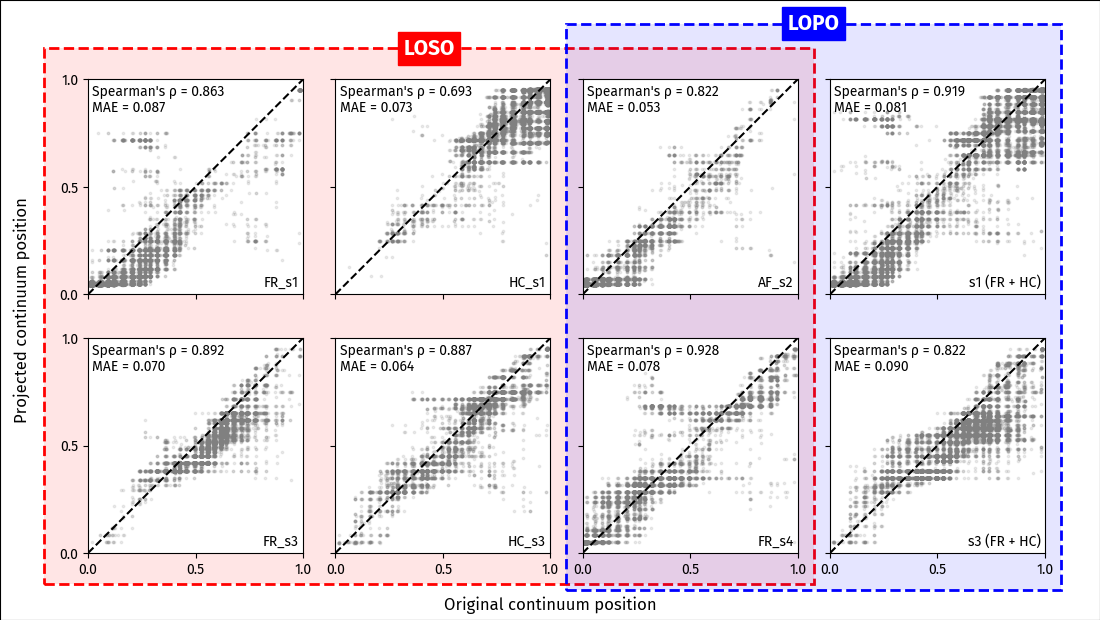

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(11, 6.2))
fig.subplots_adjust(left=0.08, right=0.95, top=0.88, bottom=0.1, hspace=0.15, wspace=0.15)
axes = axes.flatten()

l_order = ['FR_s1', 'HC_s1', 'AF_s2', "s1 (FR + HC)", 'FR_s3', 'HC_s3', 'FR_s4', "s3 (FR + HC)"]
for n, (ax, l) in enumerate(zip(axes, l_order)):
    ax.set_aspect("equal")
    ax.scatter(
        valid_dict[l]["C_full"],
        valid_dict[l]["predicted_continuum_position"],
        s=3,
        alpha=0.15,
        c="grey"
    )
    
    ax.plot([0, 1], [0, 1], linestyle="--", c="black")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.text(s=l, x=0.98, y=0.02, ha="right", va="bottom")
    ax.text(s=f"Spearman's ρ = {stat_df.loc[l,"Rho"]:.3f}", x=0.02, y=0.98, ha="left", va="top")
    ax.text(s=f"MAE = {stat_df.loc[l,"MAE"]:.3f}", x=0.02, y=0.9, ha="left", va="top")
    
    if n%4==0:
        ax.set_yticks([0,.5,1])
    else:
        ax.set_yticks([0,.5,1],[])
    if n>3:
        ax.set_xticks([0,.5,1])
    else:
        ax.set_xticks([0,.5,1],[])

group_ax = fig.add_axes([0, 0, 1, 1], zorder=-1)

r_loso = matplotlib.patches.Rectangle(
    xy=(axes[4].get_position().x0-0.04, axes[4].get_position().y0-0.05), 
    width=axes[6].get_position().x1-axes[4].get_position().x0+0.055,
    height=axes[0].get_position().y1-axes[4].get_position().y0+0.1, 
    fc="red", alpha=0.1
)
group_ax.add_patch(r_loso)
r_loso_l = matplotlib.patches.Rectangle(
    xy=(axes[4].get_position().x0-0.04, axes[4].get_position().y0-0.05), 
    width=axes[6].get_position().x1-axes[4].get_position().x0+0.055,
    height=axes[0].get_position().y1-axes[4].get_position().y0+0.1, 
    ec="red", fc="none",lw=2, ls="--"
)
group_ax.add_patch(r_loso_l)

r_lopo = matplotlib.patches.Rectangle(
    xy=(axes[6].get_position().x0-0.015, axes[6].get_position().y0-0.06), 
    width=axes[7].get_position().x1-axes[6].get_position().x0+0.03,
    height=axes[0].get_position().y1-axes[4].get_position().y0+0.15, 
    fc="blue", alpha=0.1
)
group_ax.add_patch(r_lopo)
r_lopo_l = matplotlib.patches.Rectangle(
    xy=(axes[6].get_position().x0-0.015, axes[6].get_position().y0-0.06), 
    width=axes[7].get_position().x1-axes[6].get_position().x0+0.03,
    height=axes[0].get_position().y1-axes[4].get_position().y0+0.15, 
    ec="blue", fc="none", lw=2, ls="--"
)
group_ax.add_patch(r_lopo_l)

group_ax.text(
    s="LOSO", 
    x=-0.04+(axes[6].get_position().x1+axes[4].get_position().x0+0.055)/2,
    y=0.05+axes[0].get_position().y1, 
    fontsize=15, weight=700, backgroundcolor="red", c="white", va="center", ha="center")
group_ax.text(
    s="LOPO", 
    x=(axes[7].get_position().x1+axes[6].get_position().x0)/2,
    y=axes[0].get_position().y1+0.09, 
    fontsize=15, weight=700, backgroundcolor="blue", c="white", va="center", ha="center")

fig.text(s="Projected continuum position", x=0.02, y=0.5, ha="center", va="center", rotation=90, fontsize=12)
fig.text(s="Original continuum position", x=0.5, y=0.01, ha="center", va="bottom", fontsize=12)

fig.savefig(f"{REV_PATH}105_LOSO_LOPO_scatter.png", dpi=500, format="png", bbox_inches=None)
plt.show()

# Public Data validation

## Data organization

In [1]:
import pandas as pd
from rds2py import read_rds
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from Xenium_5K_IPF_constants import WORK_PATH

%matplotlib ipympl
plt.rcParams["font.family"] = "Fira Sans" 
path = "/mnt/d/data001/xenium_IPF/xenium_rev_public/"
REV_PATH=f"{WORK_PATH}Revision/105/"

Package 'compressed_lists' is not installed.
Package 'delayedarray' is not installed.
Package 'hdf5array' is not installed.
Package 'biocframe' is not installed.
Package 'genomicranges' is not installed.
Package 'multiassayexperiment' is not installed.
Package 'iranges' is not installed.
Package 'singlecellexperiment' is not installed.
Package 'summarizedexperiment' is not installed.


In [ ]:
result = read_rds(f'{path}GSE250346.rds')


In [ ]:
row_names = result["attributes"]["meta.data"]["attributes"]["row.names"]["data"]
col_names = result["attributes"]["meta.data"]["attributes"]["names"]["data"]

In [ ]:
df = pd.DataFrame(np.nan,index=row_names,columns=col_names)

In [ ]:
for n,c in enumerate(col_names):
    df[c]=result["attributes"]["meta.data"]["data"][n]["data"]

In [ ]:
need_col = [n for n in col_names if n not in 
            ['full_cell_id','tma', 'run','CNiche', 'TNiche', 
             'lumen_id','perc_negcontrolprobe', 'perc_negcontrolcodeword',
             'perc_unassigned', 'perc_negcontrolorunassigned']]

In [ ]:
df = df[need_col].copy()

In [ ]:
fig, ax = plt.subplots(figsize=(8*10/7, 6))

tl = "patient"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    s=3,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

ax.legend(
    bbox_to_anchor=(1.01, 0.98),
    loc="upper left",
    markerscale=4,
    fontsize=11,
    edgecolor="none",
    ncols=2
)

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.7)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
fig, ax = plt.subplots(figsize=(8*10/8, 6))

tl = "sample_affect"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    s=3,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

ax.legend(
    bbox_to_anchor=(1.01, 0.98),
    loc="upper left",
    markerscale=4,
    fontsize=11,
    edgecolor="none"
)

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.8)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
fig, ax = plt.subplots(figsize=(8*10/8, 6))

tl = "percent_pathology"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    palette="viridis",
    legend=False,
    s=3,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

norm = plt.Normalize(0, 100)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
c_ax = fig.add_axes([0.85,0.7,0.02,0.25])
cbar = fig.colorbar(sm, cax=c_ax, orientation='vertical', pad=0.05)
cbar.set_ticks([0,20,40,60,80,100])

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.8)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
df_info = pd.read_csv(f"{path}sample_info.csv")

In [ ]:
pt_dict = df_info[["Donor_ID","Clinical_Diagnosis"]].set_index("Donor_ID").to_dict()["Clinical_Diagnosis"]

In [ ]:
df["diagnosis"] = df["patient"].map(pt_dict)

In [ ]:
fig, ax = plt.subplots(figsize=(8*10/8, 6))

tl = "diagnosis"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    s=3,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

ax.legend(
    bbox_to_anchor=(1.01, 0.98),
    loc="upper left",
    markerscale=4,
    fontsize=11,
    edgecolor="none",
)

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.8)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
fig, ax = plt.subplots(figsize=(32*10/8, 24))

tl = "final_lineage"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    s=1,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

ax.legend(
    # title="Final lineage",
    bbox_to_anchor=(1.01, 0.98),
    loc="upper left",
    markerscale=40,
    fontsize=44,
    edgecolor="none",
)

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.8)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
fig, ax = plt.subplots(figsize=(32*10/6, 24))

tl = "final_CT"

sns.scatterplot(
    data=df,
    x="super_adj_x_centroid",
    y="super_adj_y_centroid",
    hue=tl,
    s=1,
    linewidth=0,
    ax=ax
)

ax.set_aspect("equal")
ax.axis("off")

ax.legend(
    # title="Final lineage",
    bbox_to_anchor=(1.01, 0.98),
    loc="upper left",
    markerscale=40,
    fontsize=44,
    edgecolor="none",
    ncols=2
)

fig.subplots_adjust(left=0, top=1,bottom=0, right=0.6)

fig.savefig(f"{REV_PATH}105_sampleMap_{tl}.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
df.to_csv(f"{REV_PATH}IPFvsCTRL.csv", index_label="id")

## Profiling

In [1]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib
import copy
import seaborn as sns
import numpy as np
import os
import tqdm
from scipy.stats import spearmanr

from sklearn.metrics import pairwise_distances
from Xenium_5K_IPF_constants import WORK_PATH
import Xenium_5K_IPF_def_rev as rev

%matplotlib ipympl
plt.rcParams["font.family"] = "Fira Sans" 

REV_PATH=f"{WORK_PATH}Revision/105/"

### preparation of refference data

In [9]:
ref_dict = {
    "AT2":"AT2", 
    "AT1":"AT1", 
    "KRT5-/KRT17+": 'KRT5-/KRT17+', 
    "Basal": "Basal", 
    "Secretory": "Secretory", 
    "Goblet": "Goblet", 
    "Ciliated": "Ciliated",
    "Myofibroblast": 'Myofibroblast', 
    "COMP+ fibroblast": 'Myofibroblast', 
    "GREM1+ fibroblast": "GREM1+ fibroblast", 
    "Adventitial fibroblast": "Adventitial fibroblast", 
    "Lipofibroblast":"Lipofibroblast",
    "Smooth muscle cell":"SMC/Pericyte", 
    "Pericyte":"SMC/Pericyte", 
    "Alveolar Pericyte":"SMC/Pericyte",
    "Lymphatic": "Lymphatic", 
    "Arteriole": "Arteriole", 
    "Aerocyte": "Capillary", 
    "General capillary": "Capillary", 
    "Venule": "Venule",
    "Monocyte":"Monocyte",
    "Interstitial macrophage": "Interstitial macrophage", 
    "SPP1+ macrophage": "SPP1+ macrophage", 
    "CXCL9+ macrophage": "Not assigned", 
    "Alveolar macrophage": "Alveolar macrophage",
    "CD4+ T": "CD4+ T", 
    "CD8+ T": "CD8+ T", 
    "Treg": "Treg", 
    "NK": "NK",
    "B cell": "B cell", 
    "Plasma cell": "Plasma cell",
    "pDC": "pDC", 
    "cDC1": "cDC", 
    "cDC2": "cDC", 
    "mregDC": "Not assigned",  
    "Neutrophil": "Neutrophil", 
    "Mast cell": "Mast cell",
    "FRC-like": "Not assigned",
    "FDC-like":  "Not assigned",

}
new_celltype = sorted(set(ref_dict.values()), key=list(ref_dict.values()).index)
new_celltype.remove("Not assigned")

In [10]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/ECNP.h5ad")

In [11]:
score_df = pd.read_csv(f"{WORK_PATH}CSV/021_EcNP_score_80.csv", index_col="cell_id")
full_cp = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [12]:
ref_df = adata.obs[["sample","subtype", "EcNP"]].copy()

In [13]:
# Standardize the cell-type names.
ref_df_st = pd.DataFrame(0.0, index=new_celltype, columns=score_df.index)
for c, val in score_df.T.iterrows():
    if ref_dict[c] == "Not assigned":
        continue
    ref_df_st.loc[ref_dict[c]] += val

In [14]:
ref_df = pd.merge(ref_df, ref_df_st.T, left_index=True, right_index=True)

In [15]:
ref_df = pd.merge(ref_df, full_cp[["C_position"]], left_index=True, right_index=True, how="left")

In [16]:
total = ref_df_st.T.sum(axis=1)
valid = total > 0

proportions = ref_df_st.T.loc[valid].div(total.loc[valid], axis=0)
proportions["EcNP"] = ref_df.loc[valid, "EcNP"]

In [17]:
# grouping by neighborfood classes
class_reference = proportions.groupby("EcNP", observed=True)[new_celltype].mean()
class_reference = class_reference.div(class_reference.sum(axis=1), axis=0)

### preparation of test data

In [18]:
# test data
test_df=pd.read_csv(f"{REV_PATH}IPFvsCTRL.csv", index_col="id")
test_df = test_df[test_df["diagnosis"].isin(["Control", "IPF"])].copy()

In [19]:
test_dict = {
    'RASC':"Secretory", 
    'Secretory':"Secretory", 
    'Multiciliated':"Ciliated",
    'PNEC':"Not assigned", 
    'Basal': "Basal", 
    'Goblet': "Goblet",
    'Proliferating Airway':"Basal", 
    'AT2': "AT2", 
    'Transitional AT2': "AT2", 
    'Proliferating AT2': "AT2",
    'AT1': "AT1",
    'KRT5-/KRT17+': 'KRT5-/KRT17+',
    'Langerhans cells': "Not assigned", 
    'NK/NKT':"NK",
    'Proliferating NK/NKT': "NK",
    'Tregs':"Treg", 
    'CD4+ T-cells':"CD4+ T", 
    'CD8+ T-cells':"CD8+ T", 
    'Proliferating T-cells':"CD8+ T",
    'B cells': "B cell", 
    'Proliferating B cells': "B cell", 
    'Plasma': "Plasma cell", 
    'pDCs': "pDC",
    'cDCs':"cDC", 
    'Mast':"Mast cell",
    'Interstitial Macrophages':"Interstitial macrophage", 
    'Alveolar Macrophages':'Alveolar macrophage',
    'SPP1+ Macrophages':'SPP1+ macrophage', 
    'Neutrophils': "Neutrophil", 
    'Proliferating Myeloid':"Not assigned",
    'Migratory DCs':"Not assigned", 
    'Macrophages - IFN-activated':"Not assigned", 
    'Monocytes/MDMs': "Monocyte",
    'Basophils': "Not assigned", 
    'Venous': "Venule", 
    'Capillary': "Capillary", 
    'Lymphatic': "Lymphatic", 
    'Arteriole': "Arteriole",
    'SMCs/Pericytes': "SMC/Pericyte", 
    'Alveolar FBs': "Lipofibroblast", 
    'Proliferating FBs': "Lipofibroblast",
    'Inflammatory FBs':'GREM1+ fibroblast', 
    'Activated Fibrotic FBs':'Not assigned', 
    'Myofibroblasts':'Myofibroblast',
    'Subpleural FBs':'Adventitial fibroblast', 
    'Adventitial FBs':'Adventitial fibroblast', 
    'Mesothelial':"Not assigned"

}

In [20]:
test_df["new_celltype"]=test_df["final_CT"].map(test_dict)

In [21]:
test_df_epi = test_df[test_df["final_lineage"] == "Epithelial"].copy()

In [22]:
# epithelial centered neighborfood profiling with test data
distance=80
save_name = f"{REV_PATH}public_EcNP_score_{distance}.csv"

coords = test_df[["x_centroid", "y_centroid"]].to_numpy()
samples = test_df["sample"].to_numpy()

score_list = []


In [23]:
hoge=False
if os.path.isfile(save_name):
    score_df_test=pd.read_csv(save_name, index_col=0)
    hoge = True

if hoge:
    print("Already done!")

else:
    for idx in tqdm.tqdm(range(len(test_df_epi))):
    
        target_coord = test_df_epi.iloc[idx][
            ["x_centroid", "y_centroid"]
        ].to_numpy(dtype=float)
    
        target_sample = test_df_epi.iloc[idx]["sample"]
    
        # 同一sampleのみ
        same_sample = samples == target_sample
    
        distances = np.linalg.norm(
            coords - target_coord,
            axis=1,
        )
    
        mask = same_sample & (distances <= distance)
    
        neighbor_subtypes = test_df.loc[
            mask, "new_celltype"
        ]
    
        subtype_score = neighbor_subtypes.value_counts()
    
        full_score = {
            sub: 0.0
            for sub in new_celltype
        }
    
        full_score.update(
            subtype_score.to_dict()
        )
    
        score_list.append(full_score)
    
    score_df_test = pd.DataFrame(
        score_list,
        index=test_df_epi.index,
    )
    
    score_df_test = score_df_test.fillna(0)
    
    score_df_test.to_csv(
        save_name,
        encoding="utf-8-sig",
    )

score_df_test = score_df_test.fillna(0).copy()

Already done!


In [29]:
test_class_result= rev.assign_ecnp_class(
    query_df=score_df_test,
    class_reference=class_reference,
    subtype_columns=new_celltype,
)

In [31]:
test_class_result = test_class_result.join([score_df_test, test_df_epi], how="left")

In [32]:
continuum_classes = [
    "Preserved alveolar",
    "Pre-fibrotic",
    "Fibrotic",
    "Metaplastic",
]

continuum_mask = test_class_result["predicted_ecnp_class"].isin(continuum_classes)
test_for_continuum = test_class_result.loc[continuum_mask].copy()

In [33]:
ref_continuum_df = ref_df.loc[ref_df["C_position"].notna()].copy()
neighbor_total = ref_continuum_df[new_celltype].sum(axis=1)
ref_continuum_df = ref_continuum_df.loc[neighbor_total > 0].copy()
neighbor_total = neighbor_total.loc[neighbor_total > 0]
ref_continuum_df[new_celltype] = ref_continuum_df[new_celltype].div(neighbor_total, axis=0)

In [34]:
n_bins = 30

bin_edges = np.linspace(0, 1, n_bins + 1)
bin_centers = (np.arange(n_bins) + 0.5) / n_bins

ref_continuum_df["continuum_bin"] = pd.cut(
    ref_continuum_df["C_position"],
    bins=bin_edges,
    labels=False,
    include_lowest=True,
    right=True,
)

In [35]:
ref_prop = (
    ref_continuum_df
    .groupby("continuum_bin", observed=True)[new_celltype]
    .mean()
    .reindex(range(n_bins))
)

ref_prop = ref_prop.div(ref_prop.sum(axis=1), axis=0)

ref_prop.index.name = "reference_bin"

In [36]:
continuum_projection = rev.project_to_reference(
    query_df=test_for_continuum,
    ref_prop=ref_prop,
    bin_centers=bin_centers,
    subtype_columns=new_celltype,
    n_nearest_bins=3,
)

In [37]:
continuum_projection = continuum_projection.join(
    test_class_result[
        [
            "predicted_ecnp_class",
            "class_min_hellinger_distance",
            "class_distance_margin",
            "sample",
            "diagnosis",
            "sample_affect",
            "percent_pathology",
        ]
    ],
    how="left",
)

In [38]:
continuum_projection = continuum_projection.replace({"Unaffected": "Unaffected (Control)"})

In [39]:
sample_qc = (
    continuum_projection
    .groupby(["sample", "diagnosis", "sample_affect", "percent_pathology"],dropna=False)
    .agg(n_total=("predicted_continuum_position", "count"))
    .reset_index()
)

In [40]:
sample_continuum = (
    continuum_projection
    .groupby(["sample", "diagnosis", "sample_affect", "percent_pathology"],dropna=False)
    .agg(
        mean_continuum=("predicted_continuum_position", "mean"),
        median_continuum=("predicted_continuum_position", "median"),
        mean_distance=("min_hellinger_distance", "mean"),
        median_distance=("min_hellinger_distance", "median"),
    )
    .reset_index()
)

In [41]:
test_sample_summary = sample_qc.merge(
    sample_continuum,
    on=[
        "sample",
        "diagnosis",
        "sample_affect",
        "percent_pathology",
    ],
    how="left",
)


In [42]:
sample_affect_colors = {
    "More Affected": "#E45756",
    "Less Affected": "#F2CF5B",
    "Unaffected (Control)": "#4C78A8",
}

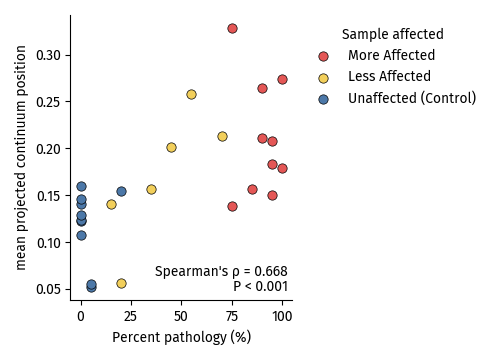

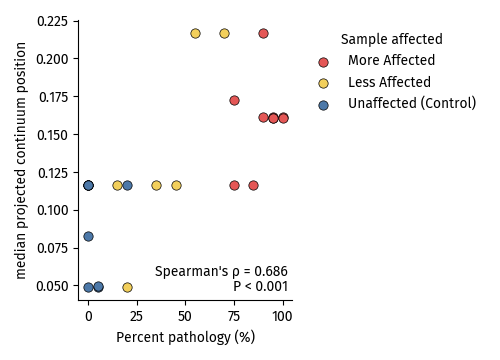

In [43]:
for md_ma in ["mean", "median"]:
    
    plot_df = test_sample_summary.dropna(
        subset=["percent_pathology", f"{md_ma}_continuum"]
    ).copy()
    rho, p_value = spearmanr(
        plot_df["percent_pathology"],
        plot_df[f"{md_ma}_continuum"],
    )
    
    fig, ax = plt.subplots(figsize=(5, 3.6))
    
    for sam in sample_affect_colors:
        group = plot_df.loc[
            plot_df["sample_affect"] == sam
        ]
    
        if group.empty:
            continue
    
        ax.scatter(
            group["percent_pathology"],
            group[f"{md_ma}_continuum"],
            s=45,
            color=sample_affect_colors[sam],
            edgecolors="black",
            linewidths=0.5,
            label=sam,
        )
    
    ax.set_xlabel("Percent pathology (%)")
    ax.set_ylabel(f"{md_ma} projected continuum position")
    
    p_text = (
        "P < 0.001"
        if p_value < 0.001
        else f"P = {p_value:.3f}"
    )
    
    ax.text(
        0.98, 0.02,
        f"Spearman's ρ = {rho:.3f}\n{p_text}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
    )

    ax.legend(
        title="Sample affected",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    plt.tight_layout()
    
    plt.savefig(f"{REV_PATH}105_Spearman_pathology_projection_CP_{md_ma}.png", dpi=500, format="png", bbox_inches=None)

In [45]:
records = []

md_ma = "mean"

plot_df = test_sample_summary.dropna(
    subset=["percent_pathology", f"{md_ma}_continuum"]
).copy()

# Spearman correlation
rho, p_value = spearmanr(
    plot_df["percent_pathology"],
    plot_df[f"{md_ma}_continuum"]
)

# Source Data
df_temp = plot_df[
    ["sample_affect", "percent_pathology", f"{md_ma}_continuum"]
].copy()

df_temp = df_temp.rename(columns={
    "sample_affect": "Sample_affected",
    "percent_pathology": "Percent_pathology",
    f"{md_ma}_continuum": "Projected_continuum_position"
})

df_temp.insert(0, "Statistic", md_ma)
df_temp["Spearman_rho"] = rho
df_temp["P_value"] = p_value

records.append(df_temp)

df_source = pd.concat(records, ignore_index=True)

df_source.to_csv(f"{REV_PATH}105_Spearman_pathology_projection_CP_{md_ma}.csv", index=True)

In [31]:
t_csv = continuum_projection[["sample","predicted_continuum_position"]].copy()

In [33]:
sample_pcp_af=continuum_projection[["sample","sample_affect", "percent_pathology"]].drop_duplicates().set_index("sample")
sample_pcp_af["pcp_mean"]=continuum_projection.groupby("sample")["predicted_continuum_position"].mean()
sample_pcp_af.sort_values("pcp_mean", inplace=True)

In [34]:
t_csv['sample'] = pd.Categorical(t_csv['sample'], categories=sample_pcp_af.index, ordered=True)
t_csv_sorted = t_csv.sort_values('sample')

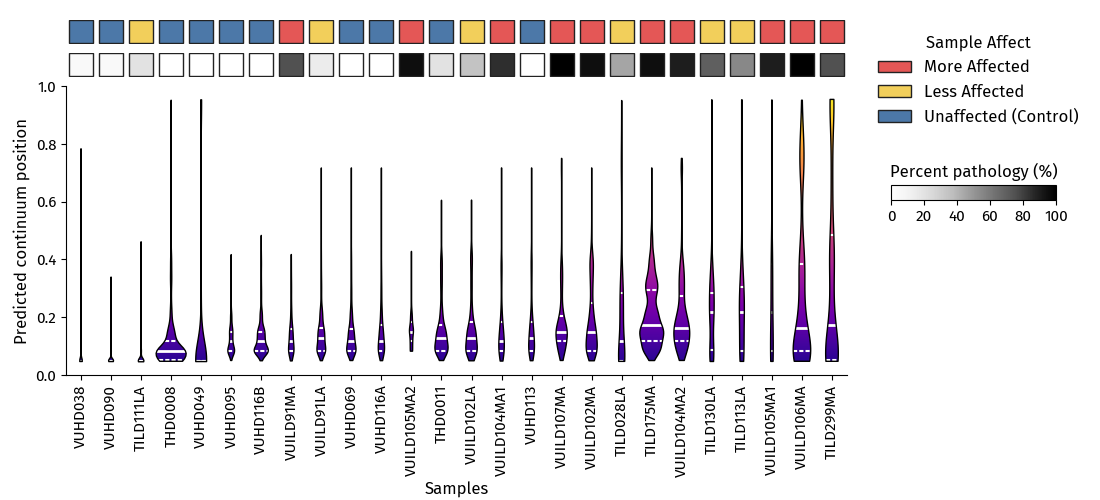

In [35]:
fig, (ax1, ax2, ax3) = plt.subplots(3,1,figsize=(11, 5), height_ratios=(1,1,12))
fig.subplots_adjust(left=0.06, right=0.77, bottom=0.25, top=0.96, hspace=0.08)
sns.violinplot(
    data=t_csv_sorted,
    x="sample",
    y="predicted_continuum_position",
    inner="quart", 
    cut=0,
    linewidth=1,
    color="white",
    ax=ax3,
    width=1,
    density_norm='count',
    bw_adjust=1.5,
    zorder=3
)

for n,line in enumerate(ax3.lines):
    if n % 3 == 1:
        line.set(linestyle="-", color="white", lw=2, zorder=2)
    else:
        line.set(linestyle=(0,(2,1)), color="white", lw=1.5, zorder=2)

orig_xlim = ax3.get_xlim()

Ny = 512
grad = np.linspace(0, 1, Ny).reshape(Ny, 1)

cmap = matplotlib.cm.plasma
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

violin_bodies = [
    c for c in ax3.collections
    if isinstance(c, matplotlib.collections.PolyCollection) and len(c.get_paths()) > 0
]
ax3.autoscale(False)

for body in violin_bodies:
    path_b = body.get_paths()[0]
    verts = path_b.vertices

    x0, x1 = verts[:, 0].min(), verts[:, 0].max()

    body.set_facecolor("none")
    body.set_edgecolor("black")
    body.set_linewidth(1.0)

    clip = matplotlib.patches.PathPatch(matplotlib.path.Path(verts), transform=ax3.transData)

    ax3.imshow(
        grad,
        origin="lower",
        aspect="auto",
        extent=[x0, x1, 0, 1],
        cmap=cmap,
        norm=norm,
        clip_path=clip,
        clip_on=True,
        zorder=1
    )

ax1.axis("off")
ax2.axis("off")

ax1.set_xlim(orig_xlim)
ax2.set_xlim(orig_xlim)
ax3.set_xlim(orig_xlim)
ax1.set_ylim(-0.05,1)
ax2.set_ylim(-0.05,1)


norm = matplotlib.colors.Normalize(vmin=0, vmax=100)
cmap = plt.get_cmap("Greys") 

for n,txt in enumerate(ax3.get_xticklabels()):
    smpl = txt.get_text()
    r1 = matplotlib.patches.Rectangle(xy=(n-0.4, 0), width=0.8, height=1, fc=sample_affect_colors[sample_pcp_af.loc[smpl, "sample_affect"]], ec="#222222")
    r2 = matplotlib.patches.Rectangle(xy=(n-0.4, 0), width=0.8, height=1, fc=cmap(norm(sample_pcp_af.loc[smpl, "percent_pathology"])), ec="#222222")
    ax1.add_patch(r1)
    ax2.add_patch(r2)
    
ax1_handles = [
    matplotlib.patches.Patch(color=color, label=label,ec="#222222")
    for label, color in sample_affect_colors.items()
]
ax1.legend(handles=ax1_handles, title="Sample Affect", loc="upper left", frameon=False, bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=12)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

ax_c = fig.add_axes([0.81, 0.6, 0.15, 0.03])
cbar = fig.colorbar(sm, cax=ax_c, ticks=[0, 20, 40, 60, 80, 100], orientation="horizontal")
cbar.ax.set_xticklabels(labels=[0,20,40,60,80,100], fontsize=11, c="black")
ax_c.set_title("Percent pathology (%)", fontsize=12)


ax3.set_ylim(0,1)
ax3.set_xlabel("Samples", fontsize=12)
ax3.set_ylabel("Predicted continuum position", fontsize=12)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

ax3.tick_params("both", labelsize=11)
ax3.tick_params("x", rotation=90)

plt.show()


plt.savefig(f"{REV_PATH}105_Cposition_sample_violin.png", dpi=500, format="png", bbox_inches=None)